# Kode 5.1 Parameter final


In [1]:
from pathlib import Path
import sys, cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
root = Path.cwd()
if not (root / "src" / "praproses.py").exists(): root = root.parent
sys.path.insert(0, str(root / "src"))
from utils_cv import baca, kontras_bercak
from praproses import praproses, simpan_param
param = {"gamma": 1.0, "clahe_clip": 2.0, "clahe_tile": 8, "penapis": "median", "kernel": 3, "sigma": 1.0, "tajam_k": 0.0}
simpan_param(param, str(root / "hasil" / "param_praproses.json"))
KANAL = 2


# Kode 5.2 Evaluasi KB sebelum/sesudah


In [2]:
label = pd.read_csv(root / "data/sintetis/label.csv")
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img = baca(str(root / "data/sintetis/citra" / d.nama_file)); md = cv2.imread(str(root / "data/sintetis/mask_daun" / d.nama_file), 0); mb = cv2.imread(str(root / "data/sintetis/mask_bercak" / d.nama_file), 0)
    out = praproses(img, param)
    baris.append([d.kondisi_cahaya, kontras_bercak(img[:, :, KANAL], md, mb), kontras_bercak(out[:, :, KANAL], md, mb)])
evaluasi = pd.DataFrame(baris, columns=["kondisi", "KB_sebelum", "KB_sesudah"])
ringkasan = evaluasi.groupby("kondisi").mean().round(2); print(ringkasan)
ringkasan.to_csv(root / "hasil/b5_kb_ringkasan.csv")


                KB_sebelum  KB_sesudah
kondisi                               
bayangan              5.54        8.57
gelap                 9.15       15.87
kontras_rendah        3.19        4.63
normal                8.15       10.13
terang                7.04        5.86


# Kode 5.3 Uji bercak palsu


In [3]:
hasil_palsu = []
for kondisi, sub in label[(label.kelas == "sehat")].groupby("kondisi_cahaya"):
    sebelum, sesudah = [], []
    for _, d in sub.iterrows():
        img = baca(str(root / "data/sintetis/citra" / d.nama_file)); md = cv2.imread(str(root / "data/sintetis/mask_daun" / d.nama_file), 0)
        out = praproses(img, param); sebelum.append(float(img[:, :, KANAL][md > 0].std())); sesudah.append(float(out[:, :, KANAL][md > 0].std()))
    hasil_palsu.append([kondisi, np.mean(sebelum), np.mean(sesudah), "Tidak"])
palsu = pd.DataFrame(hasil_palsu, columns=["Kondisi", "Simp. baku sebelum", "Simp. baku sesudah", "Muncul titik terang?"]).sort_values("Kondisi")
print(palsu.round(2)); palsu.to_csv(root / "hasil/b5_bercak_palsu.csv", index=False)


          Kondisi  Simp. baku sebelum  Simp. baku sesudah Muncul titik terang?
0        bayangan               13.35                9.69                Tidak
1           gelap                8.34                5.63                Tidak
2  kontras_rendah                9.71                9.77                Tidak
3          normal               11.40                9.83                Tidak
4          terang               10.72               12.17                Tidak


# Kode 5.5 Panel dan diagram pipeline final


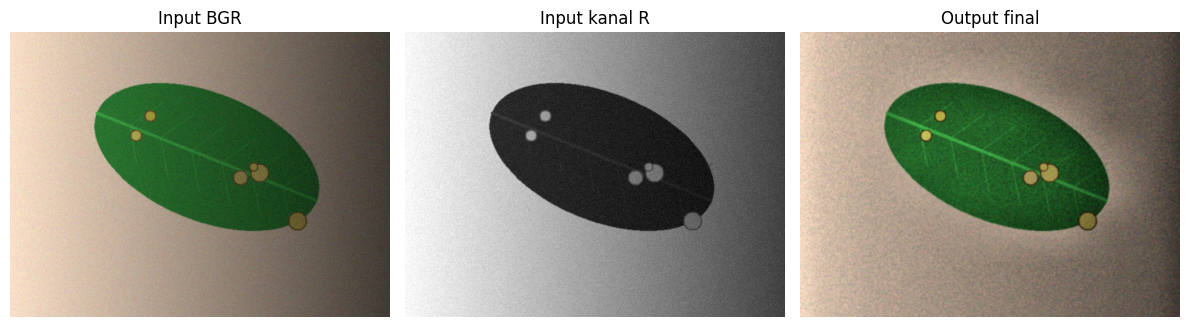

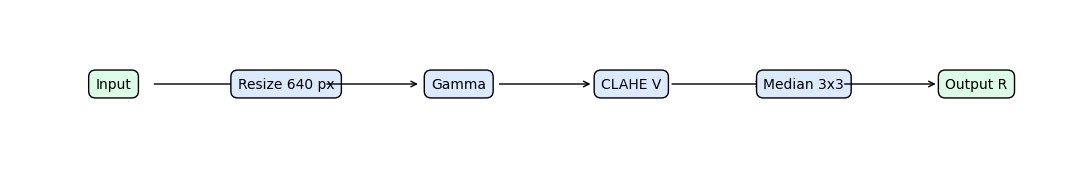

In [4]:
nama = "teh_045.png"; img = baca(str(root / "data/sintetis/citra" / nama)); out = praproses(img, param)
fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
for a, im, title in zip(ax, [img, img[:, :, KANAL], out], ["Input BGR", "Input kanal R", "Output final"]):
    a.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB) if im.ndim == 3 else im, cmap=None if im.ndim == 3 else "gray", vmin=None if im.ndim == 3 else 0, vmax=None if im.ndim == 3 else 255); a.set_title(title); a.axis("off")
plt.tight_layout(); plt.savefig(root / "hasil/b5_panel_praproses.png", dpi=150); plt.show()
fig, ax = plt.subplots(figsize=(11, 1.8)); ax.axis("off")
steps = ["Input", "Resize 640 px", "Gamma", "CLAHE V", "Median 3x3", "Output R"]
for i, s in enumerate(steps):
    ax.text(i, .5, s, ha="center", va="center", bbox=dict(boxstyle="round,pad=.5", fc="#dbeafe" if i not in (0,5) else "#dcfce7"))
    if i < len(steps)-1: ax.annotate("", (i+0.78,.5), (i+0.22,.5), arrowprops=dict(arrowstyle="->"))
ax.set_xlim(-.6, 5.6); ax.set_ylim(0, 1); plt.tight_layout(); plt.savefig(root / "hasil/b5_diagram_final.png", dpi=150); plt.show()


## Panel praproses final
![Panel praproses final](../hasil/b5_panel_praproses.png)


## Diagram pipeline final
![Diagram pipeline final](../hasil/b5_diagram_final.png)
